# Descriptive cricket analytics: explore the processed data

This notebook is for **exploration and interpretation**, not ingestion. The scripts should do repeatable data loading and metric construction; the notebook should help us inspect what those metrics mean and ask new questions.

Run the pipeline first:

```bash
uv run python scripts/run_pipeline.py --dataset wpl
```

To build the additional Stage 2 aggregates:

```bash
uv run python scripts/build_descriptive_analytics.py --dataset wpl
```

Change `DATASET` below to another processed folder such as `ipl` after ingesting that source.

In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists() and (ROOT.parent / "data" / "processed").exists():
    ROOT = ROOT.parent
DATASET = "wpl"
DATA_DIR = ROOT / "data" / "processed" / DATASET

if not DATA_DIR.exists():
    raise FileNotFoundError(f"No processed dataset at {DATA_DIR}. Run the pipeline first.")

def load_table(name: str) -> pd.DataFrame:
    path = DATA_DIR / f"{name}.csv"
    return pd.read_csv(path) if path.exists() and path.stat().st_size else pd.DataFrame()

matches = load_table("matches")
innings = load_table("innings_summary")
deliveries = load_table("deliveries")
batting = load_table("batting_summary")
bowling = load_table("bowling_summary")
phase = load_table("phase_summary")
team_summary = load_table("team_summary")
venue_summary = load_table("venue_summary")
matchups = load_table("batter_bowler_matchups")
print(f"Dataset: {DATASET} | Matches: {len(matches):,} | Innings: {len(innings):,} | Delivery events: {len(deliveries):,}")

Dataset: wpl | Matches: 88 | Innings: 178 | Delivery events: 20,656


## 1. Understand the shape and quality of the data

Before interpreting rankings, inspect schemas, data types, missingness and duplicate IDs.

In [2]:
display(matches.head())
display(deliveries.head(10))

schema = pd.DataFrame({
    "column": deliveries.columns,
    "dtype": [str(dtype) for dtype in deliveries.dtypes],
    "missing_pct": (100 * deliveries.isna().mean()).round(2).values,
})
display(schema)
print("Duplicate match IDs:", matches["match_id"].duplicated().sum())
print("Match type counts:")
display(matches["match_type"].value_counts(dropna=False).rename_axis("match_type").to_frame("matches"))

,match_id,date,season,gender,match_type,event_name,event_stage,venue,city,team_1,team_2,toss_winner,toss_decision,winner,result,win_method,data_version,source_file,player_registry_entries
0,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,NaN,"Dr DY Patil Sports Academy, Mumbai",Navi Mumbai,Mumbai Indians,Gujarat Giants,Gujarat Giants,field,Mumbai Indians,NaN,NaN,1.2.0,1358929.json,27
1,1358930,2023-03-05,2022/23,female,T20,Women's Premier League,NaN,"Brabourne Stadium, Mumbai",Mumbai,Delhi Capitals,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Delhi Capitals,NaN,NaN,1.2.0,1358930.json,27
2,1358931,2023-03-05,2022/23,female,T20,Women's Premier League,NaN,"Dr DY Patil Sports Academy, Mumbai",Navi Mumbai,Gujarat Giants,UP Warriorz,Gujarat Giants,bat,UP Warriorz,NaN,NaN,1.2.0,1358931.json,27
3,1358932,2023-03-06,2022/23,female,T20,Women's Premier League,NaN,"Brabourne Stadium, Mumbai",Mumbai,Royal Challengers Bangalore,Mumbai Indians,Royal Challengers Bangalore,bat,Mumbai Indians,NaN,NaN,1.2.0,1358932.json,27
4,1358933,2023-03-07,2022/23,female,T20,Women's Premier League,NaN,"Dr DY Patil Sports Academy, Mumbai",Navi Mumbai,Delhi Capitals,UP Warriorz,UP Warriorz,field,Delhi Capitals,NaN,NaN,1.2.0,1358933.json,27


,match_id,date,season,gender,match_type,event_name,venue,innings,batting_team,bowling_team,...,is_boundary_6,wicket_count,wicket_kinds,players_out,batter_dismissals_on_delivery,bowler_credited_wickets_on_delivery,dismissal_events_json,phase,is_super_over,source_file
0,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
1,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
2,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
3,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
4,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
5,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
6,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,True,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
7,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
8,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json
9,1358929,2023-03-04,2022/23,female,T20,Women's Premier League,"Dr DY Patil Sports Academy, Mumbai",1,Mumbai Indians,Gujarat Giants,...,False,0,NaN,NaN,0,0,[],powerplay,False,1358929.json


,column,dtype,missing_pct
0,match_id,int64,0.00
1,date,object,0.00
2,season,object,0.00
3,gender,object,0.00
4,match_type,object,0.00
5,event_name,object,0.00
6,venue,object,0.00
7,innings,int64,0.00
8,batting_team,object,0.00
9,bowling_team,object,0.00


Duplicate match IDs: 0
Match type counts:


,matches
match_type,
T20,88


## 2. Competition coverage over time

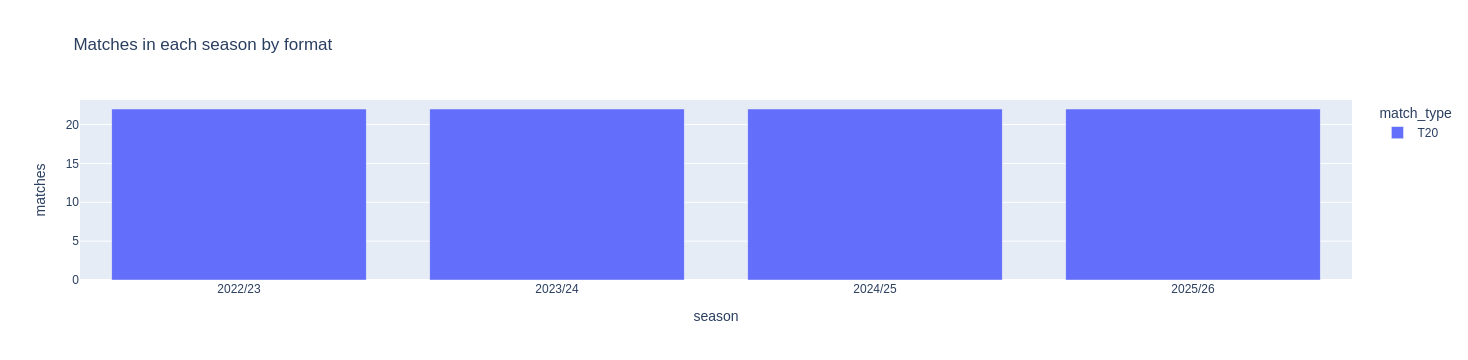

In [3]:
season_counts = matches.groupby(["match_type", "season"], dropna=False).size().reset_index(name="matches")
fig = px.bar(season_counts, x="season", y="matches", color="match_type", barmode="group", title="Matches in each season by format")
fig.show()

## 3. Batting: raw production versus rate

Runs measure volume; strike rate measures pace. Neither alone adjusts for role, entry point, opposition or match state.

,batter,gender,match_type,innings,runs,balls_faced,average,strike_rate,fours,sixes
0,NR Sciver-Brunt,female,T20,36,1348,936,49.925926,144.017094,205,15
1,MM Lanning,female,T20,35,1200,947,37.500000,126.715945,179,16
2,H Kaur,female,T20,34,1193,820,45.884615,145.487805,148,35
3,Shafali Verma,female,T20,37,1124,739,33.058824,152.097429,132,53
4,S Mandhana,female,T20,36,1025,751,31.060606,136.484687,145,29
5,EA Perry,female,T20,25,972,731,64.800000,132.968536,109,25
6,HK Matthews,female,T20,34,867,711,26.272727,121.940928,122,24
7,GM Harris,female,T20,31,819,548,30.333333,149.452555,112,28
8,RM Ghosh,female,T20,33,816,542,34.000000,150.553506,88,41
9,A Gardner,female,T20,34,811,572,25.343750,141.783217,83,34


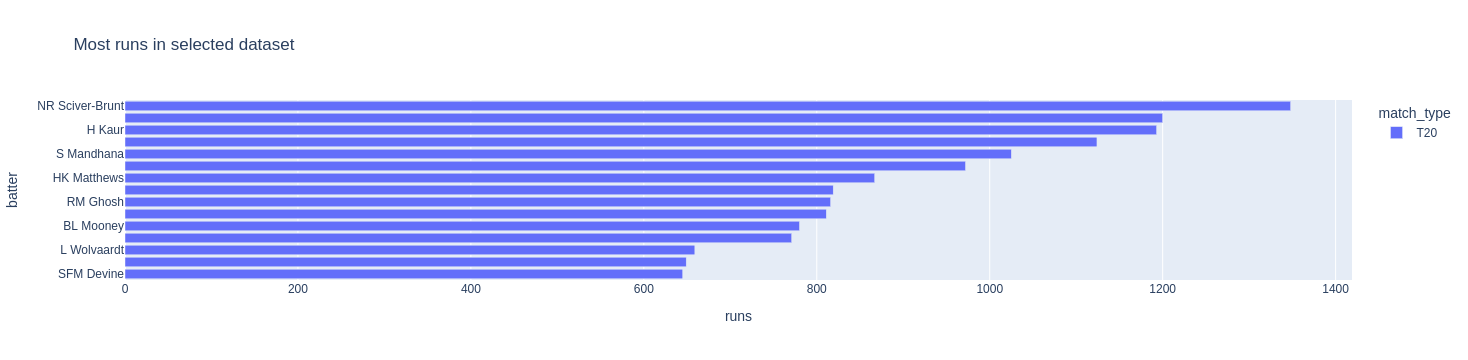

In [4]:
top_runs = batting.sort_values("runs", ascending=False).head(15)
display(top_runs[[c for c in ["batter", "gender", "match_type", "innings", "runs", "balls_faced", "average", "strike_rate", "fours", "sixes"] if c in top_runs]])
fig = px.bar(top_runs.sort_values("runs"), x="runs", y="batter", orientation="h", color="match_type", hover_data=[c for c in ["innings", "average", "strike_rate", "balls_faced"] if c in top_runs], title="Most runs in selected dataset")
fig.show()

## 4. Bowling: wickets, economy and sample size

Filter out tiny samples before drawing comparisons. The threshold below is only an exploratory default, not a universal standard.

,bowler,gender,match_type,innings,legal_balls,overs,runs_conceded,wickets,economy,scoreless_deliveries,wides,noballs
0,AC Kerr,female,T20,36,730,121.4,926,54,7.610959,293,11,0
1,HK Matthews,female,T20,34,680,113.2,863,46,7.614706,260,18,1
2,S Ecclestone,female,T20,34,768,128.0,877,43,6.851562,328,16,1
3,NR Sciver-Brunt,female,T20,36,714,119.0,960,40,8.067227,296,55,1
4,M Kapp,female,T20,34,798,133.0,804,38,6.045113,414,24,4
5,S Pandey,female,T20,35,780,130.0,936,37,7.200000,339,19,6
6,DB Sharma,female,T20,33,722,120.2,1011,34,8.401662,214,12,1
7,JL Jonassen,female,T20,24,531,88.3,685,33,7.740113,193,19,0
8,A Gardner,female,T20,34,639,106.3,931,31,8.741784,228,25,0
9,SR Patil,female,T20,24,429,71.3,624,30,8.727273,153,14,1


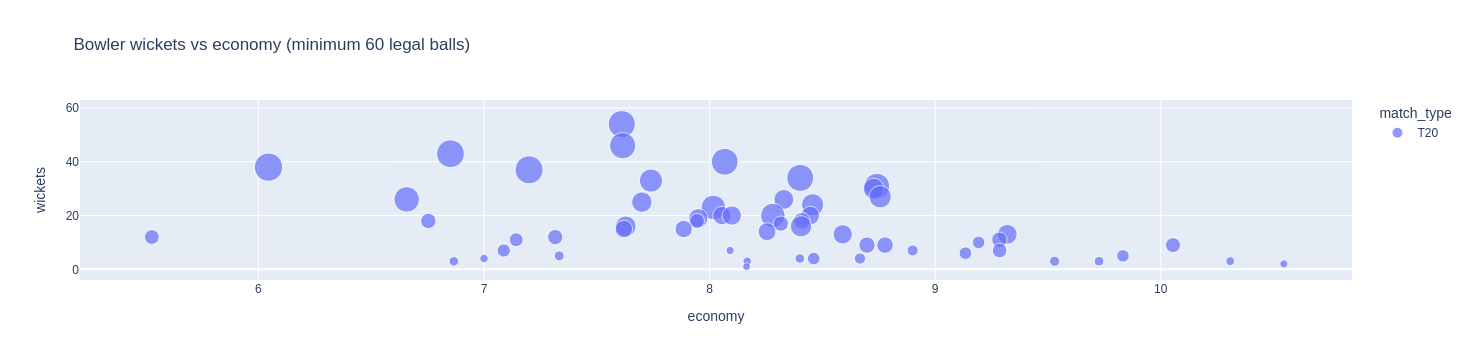

In [5]:
eligible_bowlers = bowling.loc[bowling["legal_balls"] >= 60].copy() if not bowling.empty else bowling
if not eligible_bowlers.empty:
    display(eligible_bowlers.sort_values(["wickets", "economy"], ascending=[False, True]).head(20))
    fig = px.scatter(eligible_bowlers, x="economy", y="wickets", size="legal_balls", color="match_type", hover_name="bowler", title="Bowler wickets vs economy (minimum 60 legal balls)")
    fig.show()
else:
    print("No bowlers meet the selected sample threshold.")

## 5. Team scoring profiles

,gender,match_type,team,matches,wins,losses,ties,no_results,win_pct_decisive,innings_batted,runs_scored,wickets_lost,legal_balls_faced,batting_run_rate,innings_bowled,runs_conceded,wickets_taken,legal_balls_bowled,bowling_economy
0,female,T20,Mumbai Indians,37,23,14,0,0,62.16,37,5816,204,4230,8.250,37,5429,255,4197,7.761
1,female,T20,Delhi Capitals,37,22,15,0,0,59.46,37,5672,201,4010,8.487,37,5580,245,4362,7.675
2,female,T20,Gujarat Giants,34,13,21,0,0,38.24,34,5294,239,4004,7.933,34,5492,194,3719,8.860
3,female,T20,UP Warriorz,33,11,21,1,0,34.38,33,4994,235,3806,7.873,33,5269,175,3741,8.451
4,female,T20,Royal Challengers Bengaluru,17,10,6,1,0,62.50,17,2854,92,1906,8.984,17,2768,108,1955,8.495
5,female,T20,Royal Challengers Bangalore,18,8,10,0,0,44.44,18,2736,106,2032,8.079,18,2828,100,2014,8.425


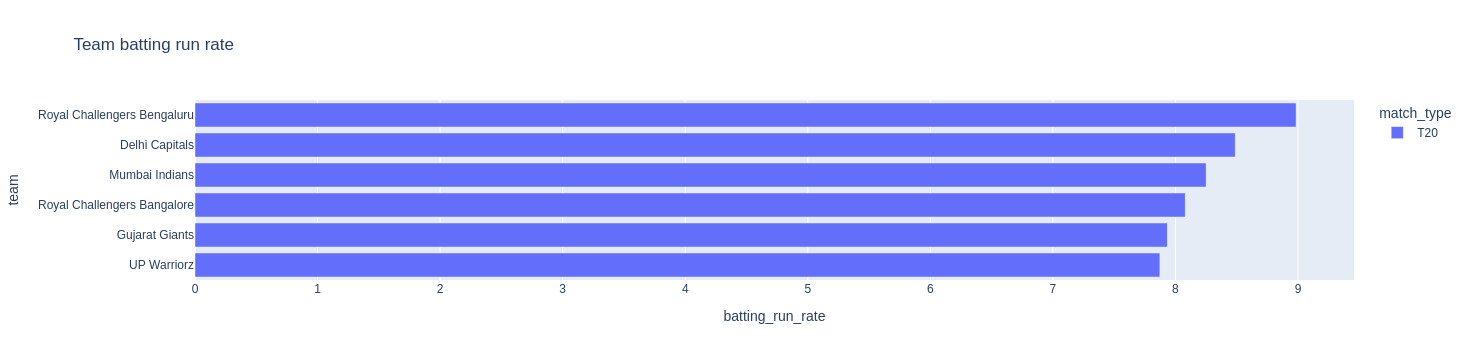

In [6]:
if not team_summary.empty:
    display(team_summary.sort_values(["match_type", "wins"], ascending=[True, False]).head(30))
    rate_data = team_summary.dropna(subset=["batting_run_rate"])
    if not rate_data.empty:
        fig = px.bar(rate_data.nlargest(20, "batting_run_rate").sort_values("batting_run_rate"), x="batting_run_rate", y="team", orientation="h", color="match_type", hover_data=[c for c in ["matches", "wins", "runs_scored", "wickets_lost"] if c in rate_data], title="Team batting run rate")
        fig.show()
else:
    print("Stage 2 tables missing. Run scripts/build_descriptive_analytics.py first.")

## 6. Scoring by phase

The phase labels use conventional T20 or 50-over ranges. Other formats are marked `not_applicable`; do not compare phases across formats without checking the definitions.

,match_type,phase,runs,legal_balls,wickets,runs_per_over
0,T20,death,7007,4307,397,9.761319
1,T20,middle,12385,9345,416,7.951846
2,T20,powerplay,7974,6336,264,7.551136


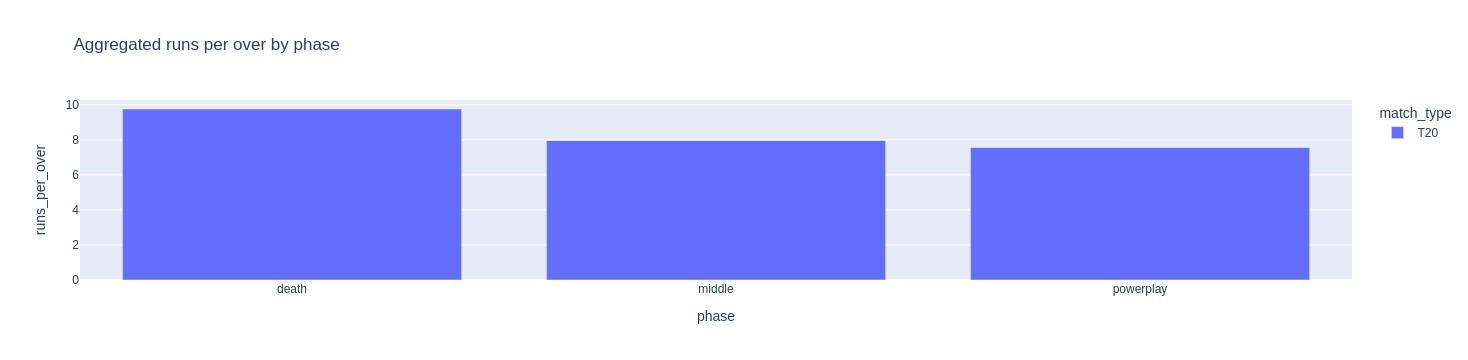

In [7]:
if not phase.empty:
    phase_plot = phase.loc[~phase["phase"].isin(["super_over", "not_applicable", "other"])].copy()
    phase_agg = phase_plot.groupby(["match_type", "phase"], as_index=False).agg(
        runs=("runs", "sum"), legal_balls=("legal_balls", "sum"), wickets=("wickets", "sum")
    )
    phase_agg["runs_per_over"] = 6 * phase_agg["runs"] / phase_agg["legal_balls"].where(phase_agg["legal_balls"] > 0)
    display(phase_agg)
    if not phase_agg.empty:
        px.bar(phase_agg, x="phase", y="runs_per_over", color="match_type", barmode="group", title="Aggregated runs per over by phase").show()

## 7. Venue summaries

Venue figures are raw aggregates and can be confounded by team strength, seasons, match format and sample size.

In [8]:
if not venue_summary.empty:
    display(venue_summary.sort_values(["matches", "average_innings_score"], ascending=[False, False]).head(25))
else:
    print("Stage 2 venue table missing. Run scripts/build_descriptive_analytics.py first.")

,gender,match_type,venue,innings,matches,average_innings_score,median_innings_score,average_wickets,total_legal_balls,total_runs,runs_per_over
0,female,T20,"M Chinnaswamy Stadium, Bengaluru",38,19,148.34,143.5,5.89,4263,5637,7.934
1,female,T20,"Kotambi Stadium, Vadodara",34,17,155.85,155.5,6.24,3881,5299,8.192
2,female,T20,"Brabourne Stadium, Mumbai",30,15,164.30,162.5,6.10,3442,4929,8.592
3,female,T20,"Dr DY Patil Sports Academy, Navi Mumbai",22,11,172.55,165.5,5.91,2555,3796,8.914
4,female,T20,"Arun Jaitley Stadium, Delhi",22,11,150.05,141.0,6.45,2549,3301,7.770
5,female,T20,"Dr DY Patil Sports Academy, Mumbai",22,11,137.14,129.0,6.05,2370,3017,7.638
6,female,T20,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,8,4,173.38,177.5,6.62,928,1387,8.968


## 8. Batter vs bowler: exploratory only

Matchup data is noisy for small samples. Always check balls faced, number of matches and dismissal definitions before making a tactical claim.

In [9]:
if not matchups.empty:
    min_balls = 24
    candidates = matchups.loc[matchups["balls_faced"] >= min_balls].copy()
    display(candidates.sort_values(["bowler_credited_wickets", "runs"], ascending=[False, True]).head(30))
else:
    print("Stage 2 matchup table missing. Run scripts/build_descriptive_analytics.py first.")

,gender,match_type,batter,bowler,recorded_events,matches,balls_faced,runs,fours,sixes,dismissals,bowler_credited_wickets,strike_rate,average
288,female,T20,S Mandhana,A Gardner,35,8,33,24,4,0,4,4,72.73,6.00
189,female,T20,HK Matthews,S Ecclestone,49,7,48,30,3,0,4,4,62.50,7.50
300,female,T20,GM Harris,M Kapp,30,6,30,23,4,0,3,3,76.67,7.67
219,female,T20,DB Sharma,AC Kerr,33,8,32,28,2,1,3,3,87.50,9.33
202,female,T20,S Mandhana,DB Sharma,27,5,27,29,5,0,3,3,107.41,9.67
190,female,T20,L Wolvaardt,S Ecclestone,30,6,30,30,3,1,3,3,100.00,10.00
125,female,T20,NR Sciver-Brunt,G Wareham,33,6,33,35,5,0,3,3,106.06,11.67
84,female,T20,HK Matthews,TP Kanwar,37,6,37,40,4,2,3,3,108.11,13.33
74,female,T20,YH Bhatia,M Kapp,40,6,39,42,8,0,3,3,107.69,14.00
59,female,T20,HK Matthews,M Kapp,55,8,54,44,8,0,3,3,81.48,14.67


## 9. Questions to carry into the next project

1. Which differences persist after splitting by match type, season and gender?
2. Which player comparisons change when minimum opportunity thresholds are applied?
3. Can we use these descriptive profiles to define features available *before* a ball or match?
4. What information is absent from the data, and would commentary or tracking actually resolve it?

These are descriptive views, not evidence of causal impact. The next modelling project should begin with a precise prediction target, a chronological holdout set and a simple baseline.